# 1. Analyse des tickets du service client

**TechDistrib** est un distributeur informatique B2B fictif : il vend du matériel et des licences à des PME, des grands comptes et des acteurs publics. Son service client reçoit environ 500 tickets par mois (retards de livraison, erreurs de facturation, retours SAV, demandes de devis...).

Aujourd'hui, **chaque ticket est lu par un agent qui l'oriente vers la bonne équipe**. Ce notebook répond à trois questions :

1. Combien de tickets, de quel type, et avec quels délais ?
2. Les engagements de délai de première réponse (SLA) sont-ils tenus ?
3. Où se trouvent les principaux leviers d'amélioration ?

> Les données sont **simulées** (voir `src/generer_donnees.py`) : aucune entreprise ni aucun client réel.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import pandas as pd

from analyse import charger_tickets, creer_reporting_excel, effet_reorientation, kpi_globaux, kpi_par

plt.rcParams.update({
    "figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.titlesize": 13, "axes.titleweight": "bold",
    "font.size": 11,
})
BLEU, ROUGE, GRIS = "#2563EB", "#DC2626", "#9CA3AF"
pd.set_option("display.precision", 1)

In [2]:
tickets = charger_tickets("../data/tickets_support.csv")
print(f"{len(tickets)} tickets du {tickets['date_creation'].min():%d/%m/%Y} au {tickets['date_creation'].max():%d/%m/%Y}")
tickets[["id_ticket", "date_creation", "canal", "message", "categorie", "priorite", "equipe_cible", "reoriente"]].head()

6000 tickets du 03/11/2025 au 30/10/2026


,id_ticket,date_creation,canal,message,categorie,priorite,equipe_cible,reoriente
0,T105481,2025-11-03 08:05:00,E-mail,Les disques SSD Samsung sont sous garantie mai...,Retour et SAV,Normale,SAV,0
1,T104641,2025-11-03 08:21:00,Portail client,Erreur de préparation sur la commande CMD-3551...,Retour et SAV,Normale,SAV,0
2,T103876,2025-11-03 08:26:00,E-mail,mise à jour du firmware impossible sur les dis...,Technique,Basse,Support technique,0
3,T100743,2025-11-03 08:30:00,Portail client,Un appareil de la commande CMD-60187 (switchs ...,Retour et SAV,Normale,SAV,1
4,T105227,2025-11-03 08:41:00,E-mail,"Je relance ma demande de la semaine dernière, ...",Commande et devis,Haute,Administration des ventes,0


## Vue d'ensemble

Le SLA (engagement de délai de première réponse) dépend de la priorité du ticket : 2 h pour un ticket urgent, 4 h en priorité haute, 8 h en priorité normale et 16 h en priorité basse (heures ouvrées).

In [3]:
kpi_globaux(tickets).rename("Valeur").to_frame()

,Valeur
Tickets,6000.0
Tickets par mois (moyenne),500.0
Délai médian de 1re réponse (h),4.1
Délai médian de résolution (h),20.6
SLA de 1re réponse respecté (%),74.3
Tickets mal orientés (%),16.0
Satisfaction moyenne (/5),3.8
Temps de tri manuel moyen (min),3.9


## Volume de tickets

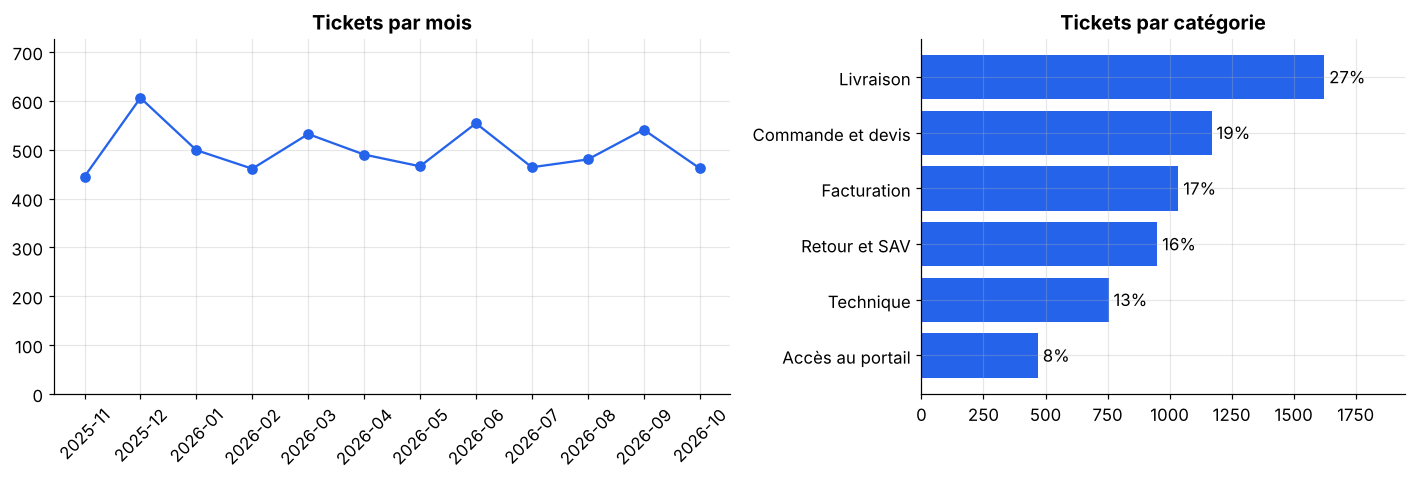

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.4, 1]})

par_mois = tickets.groupby("mois").size()
axes[0].plot(par_mois.index, par_mois.values, marker="o", color=BLEU)
axes[0].set_title("Tickets par mois")
axes[0].set_ylim(0, par_mois.max() * 1.2)
axes[0].tick_params(axis="x", rotation=45)

par_categorie = tickets["categorie"].value_counts().sort_values()
axes[1].barh(par_categorie.index, par_categorie.values, color=BLEU)
axes[1].set_title("Tickets par catégorie")
for i, v in enumerate(par_categorie.values):
    axes[1].text(v + 20, i, f"{v / len(tickets):.0%}", va="center")
axes[1].set_xlim(0, par_categorie.max() * 1.2)
plt.tight_layout()
plt.savefig("../reports/figures/volume_tickets.png", dpi=130, bbox_inches="tight")

Les **problèmes de livraison** sont le premier motif de contact (plus d'un ticket sur quatre), devant les commandes et devis. Le volume est stable d'un mois à l'autre, avec des pics le lundi et en fin de trimestre.

## Délais et satisfaction par équipe

In [5]:
kpi_par(tickets, "equipe_cible")

,tickets,reponse_mediane_h,resolution_mediane_h,sla_respecte_pct,mal_orientes_pct,satisfaction
equipe_cible,,,,,,
Logistique,1623,4.1,20.1,73.5,15.6,3.9
Support technique,1223,4.0,18.6,76.0,16.4,3.8
Administration des ventes,1169,4.1,13.1,73.0,16.4,4.1
Comptabilité clients,1035,4.1,25.1,73.7,16.8,3.7
SAV,950,4.0,37.2,75.7,15.1,3.3


Le **SAV** a les délais de résolution les plus longs et la satisfaction la plus basse : les échanges et réparations dépendent des fabricants. C'est un levier, mais il dépend en partie d'acteurs externes.

## Le coût d'un ticket mal orienté

Un ticket envoyé à la mauvaise équipe doit être réorienté avant d'être traité. Comparons les deux situations.

In [6]:
effet_reorientation(tickets)

,tickets,reponse_moyenne_h,resolution_moyenne_h,sla_respecte_pct,satisfaction
reoriente,,,,,
Bien orienté,5037,5.2,27.2,82.4,3.9
Mal orienté,963,11.9,32.5,32.0,3.3


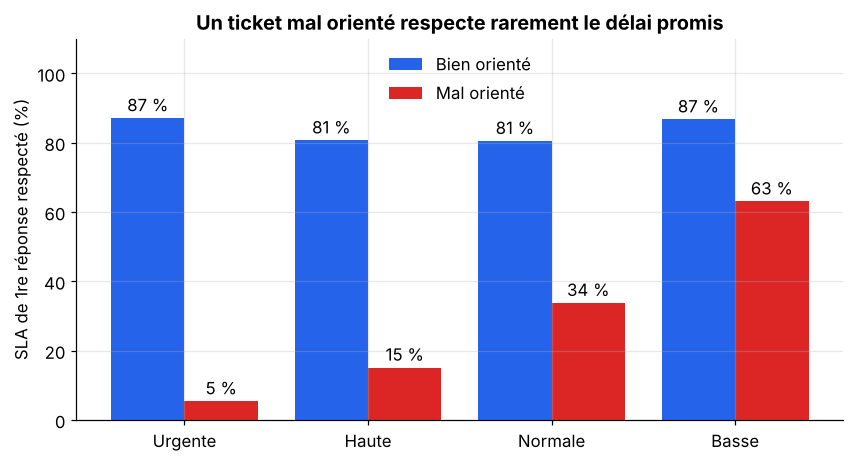

In [7]:
sla = tickets.groupby(["priorite", "reoriente"])["sla_respecte"].mean().unstack() * 100
sla = sla.loc[["Urgente", "Haute", "Normale", "Basse"]]

fig, ax = plt.subplots()
x = range(len(sla))
ax.bar([i - 0.2 for i in x], sla[0], width=0.4, color=BLEU, label="Bien orienté")
ax.bar([i + 0.2 for i in x], sla[1], width=0.4, color=ROUGE, label="Mal orienté")
for i, (a, b) in enumerate(zip(sla[0], sla[1])):
    ax.text(i - 0.2, a + 2, f"{a:.0f} %", ha="center")
    ax.text(i + 0.2, b + 2, f"{b:.0f} %", ha="center")
ax.set_xticks(list(x), sla.index)
ax.set_ylim(0, 110)
ax.set_ylabel("SLA de 1re réponse respecté (%)")
ax.set_title("Un ticket mal orienté respecte rarement le délai promis")
ax.legend(frameon=False)
plt.savefig("../reports/figures/sla_reorientation.png", dpi=130, bbox_inches="tight")

C'est le résultat principal de cette analyse : **environ 1 ticket sur 6 est mal orienté**, et ces tickets **ne respectent le délai de réponse que dans 32 % des cas, contre 82 % pour les autres**. Leur satisfaction est aussi plus basse.

## Satisfaction et délai de résolution

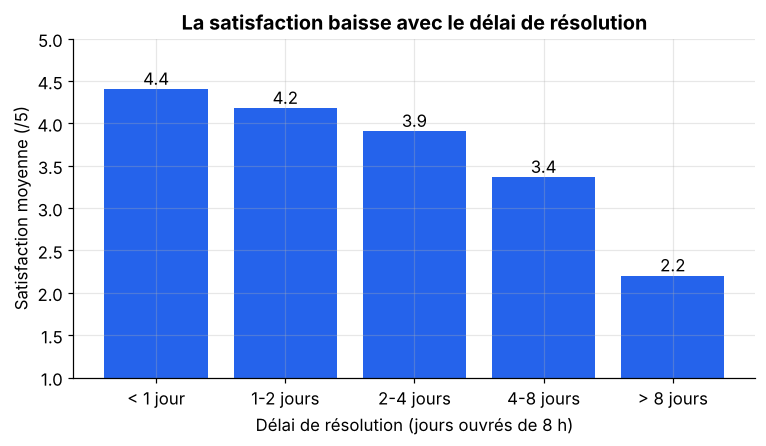

In [8]:
tranches = pd.cut(tickets["delai_resolution_h"], [0, 8, 16, 32, 64, 1000],
                  labels=["< 1 jour", "1-2 jours", "2-4 jours", "4-8 jours", "> 8 jours"])
satisfaction = tickets.groupby(tranches, observed=True)["satisfaction"].mean()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(satisfaction.index.astype(str), satisfaction.values, color=BLEU)
for i, v in enumerate(satisfaction.values):
    ax.text(i, v + 0.05, f"{v:.1f}", ha="center")
ax.set_ylim(1, 5)
ax.set_ylabel("Satisfaction moyenne (/5)")
ax.set_xlabel("Délai de résolution (jours ouvrés de 8 h)")
ax.set_title("La satisfaction baisse avec le délai de résolution")
plt.savefig("../reports/figures/satisfaction_delai.png", dpi=130, bbox_inches="tight")

## Reporting Excel

Le reporting ci-dessous est généré automatiquement. Il peut être relancé chaque semaine et partagé tel quel : synthèse, détail par équipe, par catégorie et par mois, et liste des tickets hors SLA à traiter en priorité.

In [9]:
from pathlib import Path

chemin = creer_reporting_excel(tickets, chemin=Path("../reports/reporting_support.xlsx"))
print("Reporting créé :", chemin)
print(pd.ExcelFile(chemin).sheet_names)

Reporting créé : ../reports/reporting_support.xlsx
['Synthèse', 'Par équipe', 'Par catégorie', 'Par mois', 'Tickets hors SLA']


## Conclusions

1. **L'orientation des tickets est le levier le plus simple à actionner.** Les erreurs d'orientation font chuter le respect du SLA de 82 % à 32 %.
2. **Le tri manuel prend du temps** : près de 4 minutes par ticket, soit plus de 30 heures d'agent par mois.
3. **Le SAV** concentre les délais les plus longs et la satisfaction la plus basse : à suivre dans le reporting.

➡️ Le notebook suivant teste un **tri automatique des tickets par IA** pour agir sur les deux premiers points.